<a href="https://colab.research.google.com/github/Panlyzar/project_suui2/blob/main/SUI_CV9_Velk%C3%A9_jazykov%C3%A9_modely_(new_Ollama).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 📒 CVIČENÍ 9. -  Velké jazykové modely (LLM)

V tomto cvičení se pokusíme natrénovat vlastního ChatGPT bota! 🧠🤖 V tomto cvičení využijeme template od *Liama Ottleye*, nadaného mladého streamera který se zabývá AI.


Tento sešit je inspirován jeho přístupem ale OpenAI placené modely jsou nahrazeny open-source free modely dostupné z **HuggingFace** komunity (Ollama, GPT2 tokenizer, HuggingFaceEmbeddings...).



# **Custom Knowledge ChatGPT with LangChain - Chat with PDFs**

- *Credists:* **By Liam Ottley**  (https://youtube.com/@LiamOttley)
- *Source:* https://www.youtube.com/watch?v=au2WVVGUvc8

**Content:**

0.   Installs, Imports and API Keys
1.   Loading PDFs and chunking with LangChain
2.   Embedding text and storing embeddings
3.   Creating retrieval function
4.   Creating chatbot with chat memory








# 🛑 Než začneme
- změňte si typ běhového prostředí na **T4 GPU**
- lze to udělat vprovo nahoře v indikátorů zatížení prostředí -> `šipka dolů` -> `Změnit typ běhového prostředí ` -> `T4 GPU` -> `Uložit`
- díky tomu budeme moct pro trénování CNN využívat sílu GPU, což nám ušetří 10-ti násobek času

#  **0. Installs, Imports and API Key**s

In [ ]:
# Instalace nejnovějších, kompatibilních balíčků
!pip install -q transformers faiss-cpu pypdf tiktoken
!pip install -q langchain langchain-community langchain-faiss langchain-text-splitters pypdf tiktoken transformers faiss-cpu sentence-transformers ollama requests==2.32.4

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 31.4/31.4 MB 74.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 323.9/323.9 kB 31.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.5/2.5 MB 24.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.9/50.9 kB 2.1 MB/s eta 0:00:00


In [ ]:
!pip list | grep langchain

langchain                                0.3.27
langchain-community                      0.3.27
langchain-core                           0.3.79
langchain-faiss                          0.1.1
langchain-text-splitters                 0.3.11


In [ ]:
# Instalace a spuštění Ollama serveru
!curl -fsSL https://ollama.com/install.sh | sh

import subprocess
import time

# Spuštění Ollama serveru na pozadí
process = subprocess.Popen(['ollama', 'serve'], stdout=subprocess.PIPE, stderr=subprocess.PIPE)
print("Spouštím Ollama server...")
time.sleep(10) # Dáme mu chvilku na start
print("Ollama server by měl běžet.")

>>> Installing ollama to /usr/local
>>> Downloading Linux amd64 bundle
######################################################################## 100.0%
>>> Creating ollama user...
>>> Adding ollama user to video group...
>>> Adding current user to ollama group...
>>> Creating ollama systemd service...
>>> The Ollama API is now available at 127.0.0.1:11434.
>>> Install complete. Run "ollama" from the command line.
Spouštím Ollama server...
Ollama server by měl běžet.


In [ ]:
# Stažení modelu (gemma:2b je malý a rychlý)
!ollama pull gemma:2b

In [ ]:
# Import common ML libs
import os
import pandas as pd
import matplotlib.pyplot as plt

# Import libs for work with LM
from transformers import GPT2TokenizerFast
from langchain_community.document_loaders import PyPDFLoader
from langchain_text_splitters import RecursiveCharacterTextSplitter

from langchain_community.embeddings import HuggingFaceEmbeddings
from langchain_community.vectorstores import FAISS

from langchain.chains.question_answering import load_qa_chain
from langchain_community.llms import Ollama  # OpenAI -> Ollama
from langchain.chains import ConversationalRetrievalChain

## 🦙 Ollama
- jedna z předních open-source firem zabývající se vývojem AI
- zaměření hlavně na velké jazykové modely (LM)
- jejich modely najdete hlavně na platformě (https://huggingface.co/)
- **pro získání API tokenu si musíte založit Hugging Face 🤗 účet:**
  - Přístup na platformu: https://huggingface.co/
  - 1. Registruj se
  - 2. Vyberte kartu po kliknutí na svou miniaturu profilu vpravo nahoře `Access Tokens` (https://huggingface.co/settings/tokens)
  - 3. Klikněte na `Create new token`
  - 4. Zkopírujte si klíč a bezpečně jej ulož!

# Vložte HuggingFace API klíč 🔑
- Vložte svůj *HuggingFace* API klíč prosím do sekce *Tajné údaje* v Google Colab, alias bude `HF_TOKEN_API`.



In [ ]:
# Load your token from Secrets
from google.colab import userdata
HF_TOKEN_API = userdata.get('HF_TOKEN_API')

In [ ]:
# Insert HF API token to system env
os.environ["HF_TOKEN"] = HF_TOKEN_API

In [ ]:
# Check
os.environ["HF_TOKEN"][:3]

'hf_'

# **1. 📃 Loading PDFs and chunking with LangChain**

# 🧩 Chunking
při zpracování textových souborů znamená rozdělení textu na zpracovatelné části, jako jsou stránky, věty nebo odstavce, za účelem efektivnějšího zpracování a analýzy.

## Načtení datové sady pro Language Model
- k tomu aby nám byl jakýkoliv LM k něčemu platný je třeba jej napřed natrénovat
- jako každý jiný ML model, potřebuje k tomuto účelu trénovací data
- v toto případě to bude libovolný PDF či textový dokument / dokumenty

## 🪓 Metoda 1: Hrubý chunking
- po stránkách, hodí se pro krátké dokumenty. Je rychlejší a přímočarý.

#### *Attention Is All You Need*
- jedná se článek pojednávající zavedení pojmu pozornosti pro vélké jazykové modely
- dále pojednává o využití jazykových transformátorů
- článek je z roku 2017
- odkaz: [Attention Is All You Need (2017)](https://drive.google.com/file/d/1VjTP02M6kDH6maVdzrqxIEwVtAdMWfCl/view?usp=drive_link)
- stáhni si ho lokálně

In [ ]:
#Google Colab upload form -upload your AttentionIsAllYouNeed.pdf here
from google.colab import files
data = files.upload()

Saving AttentionIsAllYouNeed.pdf to AttentionIsAllYouNeed (1).pdf


In [ ]:
# Simple method - Split by pages
document_fp = r"/content/AttentionIsAllYouNeed.pdf"
loader = PyPDFLoader(document_fp)
pdf_pages = loader.load_and_split()

# Save, you can choose only some pages here
pages = pdf_pages[:]

In [ ]:
pages[0].page_content

'Attention Is All You Need\nAshish Vaswani∗\nGoogle Brain\navaswani@google.com\nNoam Shazeer∗\nGoogle Brain\nnoam@google.com\nNiki Parmar∗\nGoogle Research\nnikip@google.com\nJakob Uszkoreit∗\nGoogle Research\nusz@google.com\nLlion Jones∗\nGoogle Research\nllion@google.com\nAidan N. Gomez∗†\nUniversity of Toronto\naidan@cs.toronto.edu\nŁukasz Kaiser ∗\nGoogle Brain\nlukaszkaiser@google.com\nIllia Polosukhin∗‡\nillia.polosukhin@gmail.com\nAbstract\nThe dominant sequence transduction models are based on complex recurrent or\nconvolutional neural networks that include an encoder and a decoder. The best\nperforming models also connect the encoder and decoder through an attention\nmechanism. We propose a new simple network architecture, the Transformer,\nbased solely on attention mechanisms, dispensing with recurrence and convolutions\nentirely. Experiments on two machine translation tasks show these models to\nbe superior in quality while being more parallelizable and requiring signiﬁcantl

## 🔪 Metoda 2: Podrobný chunking
- po krátkých řetězcích/odstavcích/jkapitolách, hodí se pro všechny dokumenty. Je pomalejší a komplikovanější, ale umožňuje lepší nastavení parametrů.

### 🧩 Tokenizace
- je proces rozdělení textu na menší jednotky, nazývané tokeny. Tyto tokeny mohou být slova, fráze, věty, nebo dokonce jednotlivé znaky
- playground: https://platform.openai.com/tokenizer

In [ ]:
#Step 1: Load text source
text = ""
for p in pages:
  text += p.page_content

text

'Attention Is All You Need\nAshish Vaswani∗\nGoogle Brain\navaswani@google.com\nNoam Shazeer∗\nGoogle Brain\nnoam@google.com\nNiki Parmar∗\nGoogle Research\nnikip@google.com\nJakob Uszkoreit∗\nGoogle Research\nusz@google.com\nLlion Jones∗\nGoogle Research\nllion@google.com\nAidan N. Gomez∗†\nUniversity of Toronto\naidan@cs.toronto.edu\nŁukasz Kaiser ∗\nGoogle Brain\nlukaszkaiser@google.com\nIllia Polosukhin∗‡\nillia.polosukhin@gmail.com\nAbstract\nThe dominant sequence transduction models are based on complex recurrent or\nconvolutional neural networks that include an encoder and a decoder. The best\nperforming models also connect the encoder and decoder through an attention\nmechanism. We propose a new simple network architecture, the Transformer,\nbased solely on attention mechanisms, dispensing with recurrence and convolutions\nentirely. Experiments on two machine translation tasks show these models to\nbe superior in quality while being more parallelizable and requiring signiﬁcantl

In [ ]:
#Or: Convert pages to docs
texts = [p.page_content for p in pages]
texts

In [ ]:
# Advanced method - Split by chunk

# Use GPT2 tokenizer to create context-bound tokens
tokenizer = GPT2TokenizerFast.from_pretrained("gpt2")

# Step 2: Create function to count tokens
def count_tokens(text: str) -> int:
    return len(tokenizer.encode(text))

# Step 3: Split text into chunks
text_splitter = RecursiveCharacterTextSplitter(
    # Set a really small chunk size, just to show.
    chunk_size = 512,
    chunk_overlap  = 24,
    length_function = count_tokens,
)

docs = text_splitter.create_documents(texts)

In [ ]:
# Result is many LangChain 'Documents' around 500 tokens or less (Recursive splitter sometimes allows more tokens to retain context)
type(docs[0])

langchain_core.documents.base.Document

In [ ]:
docs[0].page_content

'Attention Is All You Need\nAshish Vaswani∗\nGoogle Brain\navaswani@google.com\nNoam Shazeer∗\nGoogle Brain\nnoam@google.com\nNiki Parmar∗\nGoogle Research\nnikip@google.com\nJakob Uszkoreit∗\nGoogle Research\nusz@google.com\nLlion Jones∗\nGoogle Research\nllion@google.com\nAidan N. Gomez∗†\nUniversity of Toronto\naidan@cs.toronto.edu\nŁukasz Kaiser ∗\nGoogle Brain\nlukaszkaiser@google.com\nIllia Polosukhin∗‡\nillia.polosukhin@gmail.com\nAbstract\nThe dominant sequence transduction models are based on complex recurrent or\nconvolutional neural networks that include an encoder and a decoder. The best\nperforming models also connect the encoder and decoder through an attention\nmechanism. We propose a new simple network architecture, the Transformer,\nbased solely on attention mechanisms, dispensing with recurrence and convolutions\nentirely. Experiments on two machine translation tasks show these models to\nbe superior in quality while being more parallelizable and requiring signiﬁcantl

In [ ]:
len(docs)

18

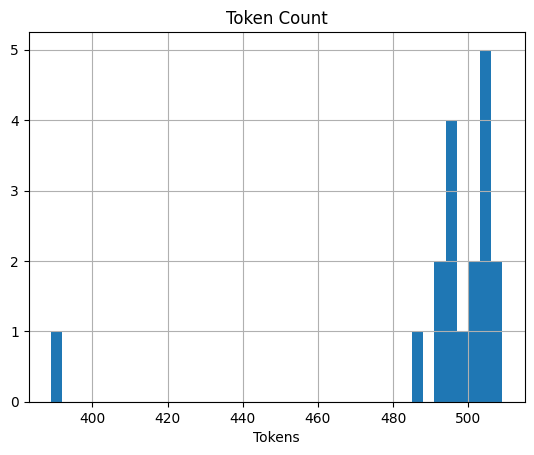

In [ ]:
# Quick data visualization to ensure chunking was successful

# Create a list of token counts
token_counts = [count_tokens(d.page_content) for d in docs]

# Create a DataFrame from the token counts
df = pd.DataFrame({'Token Count': token_counts})

# Create a histogram of the token count distribution
df.hist(bins=40)
plt.xlabel("Tokens")

# Show the plot
plt.show()

# **2. Embed text and store embeddings**

### 🧩 Embedding
- **transformuje položky, jako jsou slova, na čísla - vektory**
- v číselném prostoru **seskupuje podobné položky blíže k sobě**, což usnadňuje rozpoznávání vzorů a vztahů.
- je to vlastně **chytrá vektorizace slov**
- často se využívají již natrénované algoritmy, jako jsou `Word2Vec` nebo `GloVe`, které se tyto reprezentace učí z rozsáhlých textových souborů.

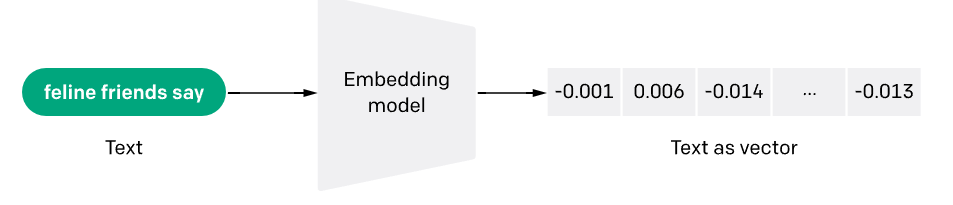

In [ ]:
from langchain_community.embeddings import HuggingFaceEmbeddings

# all-MiniLM-L6-v2 je malý, rychlý model podporující češtinu z kategorie sentence-transformers
# link: https://huggingface.co/sentence-transformers/all-MiniLM-L6-v2
model_name = "all-MiniLM-L6-v2"
embeddings = HuggingFaceEmbeddings(model_name=model_name)

# Create vector database
db = FAISS.from_documents(docs, embeddings)

# **3. Setup retrieval function**

### 🧩 Retrieval function
- **funkce vyhledávání** sloužící k z**ískávání relevantních dat** nebo informací z databáze nebo souboru dat
- data hledá **na základě** konkrétních kritérií nebo **dotazů**
- tato funkce je klíčová v systémech pro vyhledávání informací, vyhledávačích a správě databází

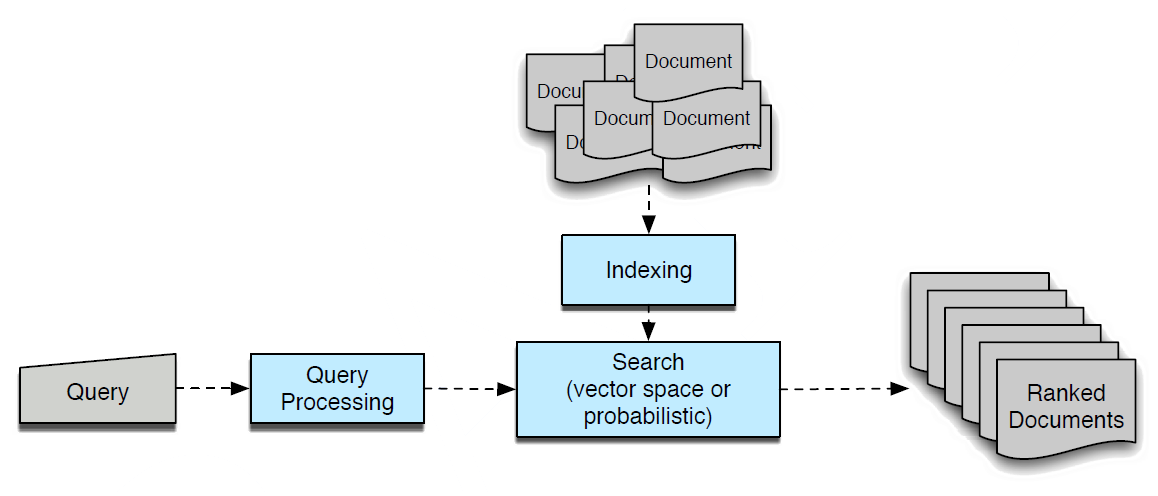

In [ ]:
# Check similarity search is working
query = "Who created transformers?"
docs = db.similarity_search(query)
docs

[Document(id='edd74fc3-7c59-4da6-87b5-e35b8c8e95a6', metadata={}, page_content='Here, the encoder maps an input sequence of symbol representations (x1,...,x n) to a sequence\nof continuous representations z = (z1,...,z n). Given z, the decoder then generates an output\nsequence (y1,...,y m) of symbols one element at a time. At each step the model is auto-regressive\n[9], consuming the previously generated symbols as additional input when generating the next.\nThe Transformer follows this overall architecture using stacked self-attention and point-wise, fully[9], consuming the previously generated symbols as additional input when generating the next.\nThe Transformer follows this overall architecture using stacked self-attention and point-wise, fully\nconnected layers for both the encoder and decoder, shown in the left and right halves of Figure 1,\nrespectively.\n3.1 Encoder and Decoder Stacks\nEncoder: The encoder is composed of a stack of N = 6 identical layers. Each layer has two\ns

In [ ]:
len(docs)

4

In [ ]:
# ZMĚNA: Používáme Ollama(model="gemma:2b") místo OpenAI()
chain = load_qa_chain(Ollama(model="gemma:2b"), chain_type="stuff")

query = "Who created transformers?"
docs = db.similarity_search(query)

result = chain.invoke({"input_documents": docs, "question": query})
print(result['output_text'])

The context does not mention who created transformers, so I cannot answer this question from the provided context.


## 🧩 Textové transformátory

- *10 mins explain* 📽: https://www.youtube.com/watch?v=FWFA4DGuzSc

**Definice:**
- je typ umělé neuronové sítě používaný v zpracování přirozeného jazyka (NLP)
- klíčovým prvkem je mechanismus pozornosti (attention mechanism) -  ten umožňuje modelu soustředit jen na vybrané části vstupního textu
- tato vlastnost umožňuje transformátorům efektivněji zpracovávat dlouhé sekvence dat a lépe zachytit kontext a vztahy mezi slovy v textu.

**Architektura:**
 - Transformátory se skládají **enkodérů** (pro zpracování vstupu)a  **dekodérů** (pro generování výstupu)
- většinou se zde využívají hluboké neuronové sítě, jakou jsou `RNN` a `LSTM`

 - Modely založené na transformátorech, jako je *GPT (Generative Pre-trained Transformer)* nebo *BERT (Bidirectional Encoder Representations from Transformers)*, přinesly významné zlepšení v mnoha úlohách NLP, jako je strojový překlad, automatické generování textu, sémantická analýza a další.

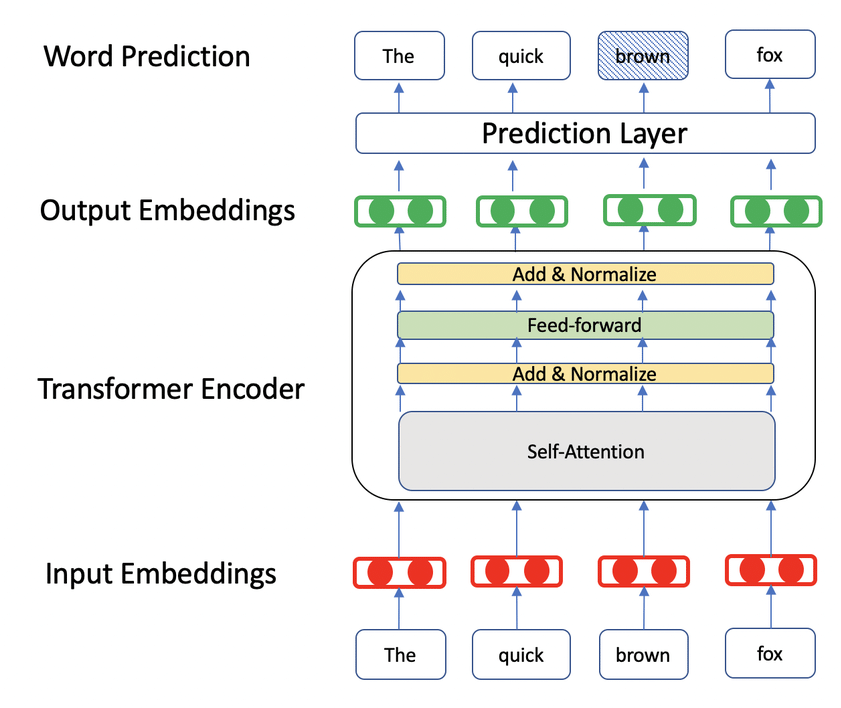

# **4. Create simple chatbot with chat memory**

In [ ]:
from IPython.display import display
import ipywidgets as widgets

# ZMĚNA: Používáme Ollama(model="gemma:2b") místo OpenAI()
qa = ConversationalRetrievalChain.from_llm(Ollama(model="gemma:2b"), db.as_retriever())

In [ ]:
chat_history = []

def on_submit(_):
    query = input_box.value
    input_box.value = ""

    if query.lower() == 'exit':
        print("Thank you for using the State of the Union chatbot!")
        return

    result = qa({"question": query, "chat_history": chat_history})
    chat_history.append((query, result['answer']))

    display(widgets.HTML(f'<b>User:</b> {query}'))
    display(widgets.HTML(f'<b><font color="blue">Chatbot:</font></b> {result["answer"]}'))

print("Welcome to the Transformers chatbot! Type 'exit' to stop.")

input_box = widgets.Text(placeholder='Please enter your question:')
input_box.on_submit(on_submit)

display(input_box)

Welcome to the Transformers chatbot! Type 'exit' to stop.


Text(value='', placeholder='Please enter your question:')

HTML(value='<b>User:</b> Tranformer')

HTML(value='<b><font color="blue">Chatbot:</font></b> The Transformer is a sequence transduction model based s…

HTML(value='<b>User:</b> hmm')

HTML(value='<b><font color="blue">Chatbot:</font></b> Sure. The architecture of the Transformer model is as fo…

### 🧠 Úkol 1: Silnější LLM model

Místo modelu Gemma použij model [Llama-3.1-8B-Instruct](https://huggingface.co/meta-llama/Llama-3.1-8B-Instruct).

Jak na to?
1. Zjisti alias modelu, něco ve tvaru "llama3.1"
2. Pullni model pomocí

```
!ollama pull <model_alias>
```
3. Znova zbuildi QA chain (spusť chat)

